Linear regression - exercise 2
    Imagine that you are a data scientist and your friend is a jeweler. Your friend's jewelry store is visited by a huge number of customers who bring diamonds to sell. The number of interested people is so large that the friend is not able to asses value of the stones - due to other responsibilities. As a data expert, you offer to automate the valuation process using machine learning. You ask your friend to provide the historical data he relied on when doing previous valuations. Your task is to analyze and clean the data, and try to build a linear regression model that will determine the price of a diamond based on its properties.

Description of the data received:

    carat - a carat is the physical mass of a diamond. One carat is 0.20 grams.
    cut - the quality of the cut. The more accurately a diamond is cut, the better quality it is and the more eye-catching it is.
    color - diamonds come in colors ranging from light yellow to light brown. In the dataset, "J" denotes the worst color and "D" the best.
    clarity - clarity. Diamonds can have blemishes, which are often visible only under proper magnification. Clarity is described by several values: I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best).
    depth - the depth of a diamond is its height in millimeters measured from the sphere (bottom cone) to the table (flat, top surface).
    table - the width of the top of the diamond relative to the widest point. The larger the value, the more brilliance the diamond has.
    price - the price of the diamond in US dollars.
    x - the total length of the diamond (in mm).
    y - the total width of the diamond (in mm)
    z - the total depth of the diamond (in mm)
1. Transfer the data file (diamonds.csv) to the execution environment of your notebook or to Google drive.
2. Import all necessary methods from libraries (or modules from these libraries).
3. Load the data frame file into the Pandas library. Assign the data frame to a variable named diamonds_df.
4. Display the first dozen or so data records to see how the data looks.
5. Remove unnecessary columns from the dataset.
6. Using the methods you have learned, verify the presence of missing values in the dataset.
7. Use the appropriate seaborn library tool to check the relationships between variables and the distribution of variable values on a single graph.
8. Generate and visualize the correlation matrix. Exclude variables with low correlation coefficient from the dataset. You can verify the linearity of the correlation of the remaining variables on scatter plots against the independent variable (price).
9. Using the selected graphs, check for outliers. Use scatter plots of the selected variables and the dependent variable price to accurately identify observations that have outliers. Use the method of your choice (e.g., reading from the graph and filtering, IQR method) to remove outliers.
10. Divide the dataset into training and test datasets.
11. Define and train the model using the training data. Make predictions on the test data.
12. Save the prepared dataset to .csv file. You will use it to build more models during this day.

In [80]:
import pandas as pd

diamonds_df = pd.read_csv("data/diamonds.csv")
diamonds_df.head(15)

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,6,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,7,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,8,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,9,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,10,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


In [81]:
# Drop unnecessary columns
diamonds_df = diamonds_df.drop(columns=["Unnamed: 0"])
diamonds_df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [82]:
# Check missing data

diamonds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [83]:
diamonds_df.isnull().sum()

# No null values in df


carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [84]:
# check categorical values

diamonds_categorical_df = diamonds_df[['cut', 'color', 'clarity']]

diamonds_categorical_df.nunique()

cut        5
color      7
clarity    8
dtype: int64

In [85]:
print(diamonds_df["cut"].unique())
print(diamonds_df["color"].unique())
print(diamonds_df["clarity"].unique())

['Ideal' 'Premium' 'Good' 'Very Good' 'Fair']
['E' 'I' 'J' 'H' 'F' 'G' 'D']
['SI2' 'SI1' 'VS1' 'VS2' 'VVS2' 'VVS1' 'I1' 'IF']


In [86]:
orders = {
    "cut":["Fair", "Good", "Very Good", "Premium", "Ideal"],
    "color":["J", "I", "H", "G", "F", "E", "D"],
    "clarity":["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
}

quality_df = diamonds_df.copy()
for column, order in orders.items():
    quality_df[f"{column}_rank"] = quality_df[column].map(
        {category: rank for rank, category in enumerate(order, start = 1)}
    )
quality_df.head()

# now quality_df(copy of diamonds_df) include numeric (rank) values for categorical variables

,carat,cut,color,clarity,depth,table,price,x,y,z,cut_rank,color_rank,clarity_rank
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,5,6,2
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,4,6,3
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,2,6,5
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,4,2,4
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,2,1,2


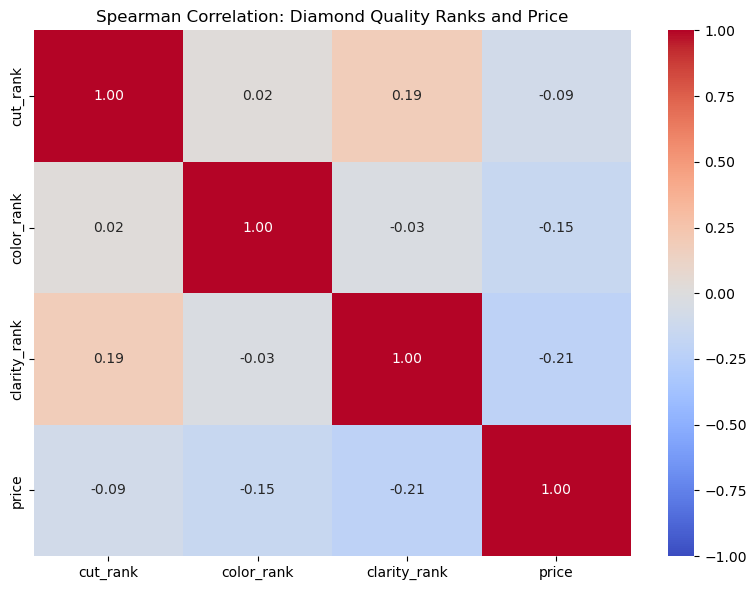

In [87]:
# Spearman correlation is appropriate for the ordinal quality ranks.
import matplotlib.pyplot as plt
import seaborn as sns

quality_corr_columns = ["cut_rank", "color_rank", "clarity_rank", "price"]
quality_spearman_corr = quality_df[quality_corr_columns].corr(method="spearman")

# Visualize rank correlations, including each quality grade's association with price.
plt.figure(figsize=(8, 6))
sns.heatmap(
    quality_spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Spearman Correlation: Diamond Quality Ranks and Price")
plt.tight_layout()
plt.show()

## Interpreting the Spearman Correlation

The quality grades are ordinal categories: they have a meaningful order, but the gaps between grades are not measurements with equal spacing. We therefore show them separately from the Pearson correlation matrix for continuous numeric measurements and use Spearman correlation, which evaluates monotonic relationships using ranks.

In this dataset, the Spearman correlations with `price` are weak and negative: `cut_rank` is **-0.09**, `color_rank` is **-0.15**, and `clarity_rank` is **-0.21**. This describes the overall unadjusted trend in these records; it does not mean that improving a diamond's quality lowers its price. Price is strongly influenced by carat, and the distribution of carat can differ across quality grades. These correlations alone are not a reason to discard the quality features from a predictive model.

In [88]:
diamonds_numeric_df = diamonds_df.copy()
diamonds_numeric_df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [89]:
diamonds_numeric_df = diamonds_numeric_df.drop(columns=["cut", "color", "clarity"])
diamonds_numeric_df.head(5)

,carat,depth,table,price,x,y,z
0,0.23,61.5,55.0,326,3.95,3.98,2.43
1,0.21,59.8,61.0,326,3.89,3.84,2.31
2,0.23,56.9,65.0,327,4.05,4.07,2.31
3,0.29,62.4,58.0,334,4.20,4.23,2.63
4,0.31,63.3,58.0,335,4.34,4.35,2.75


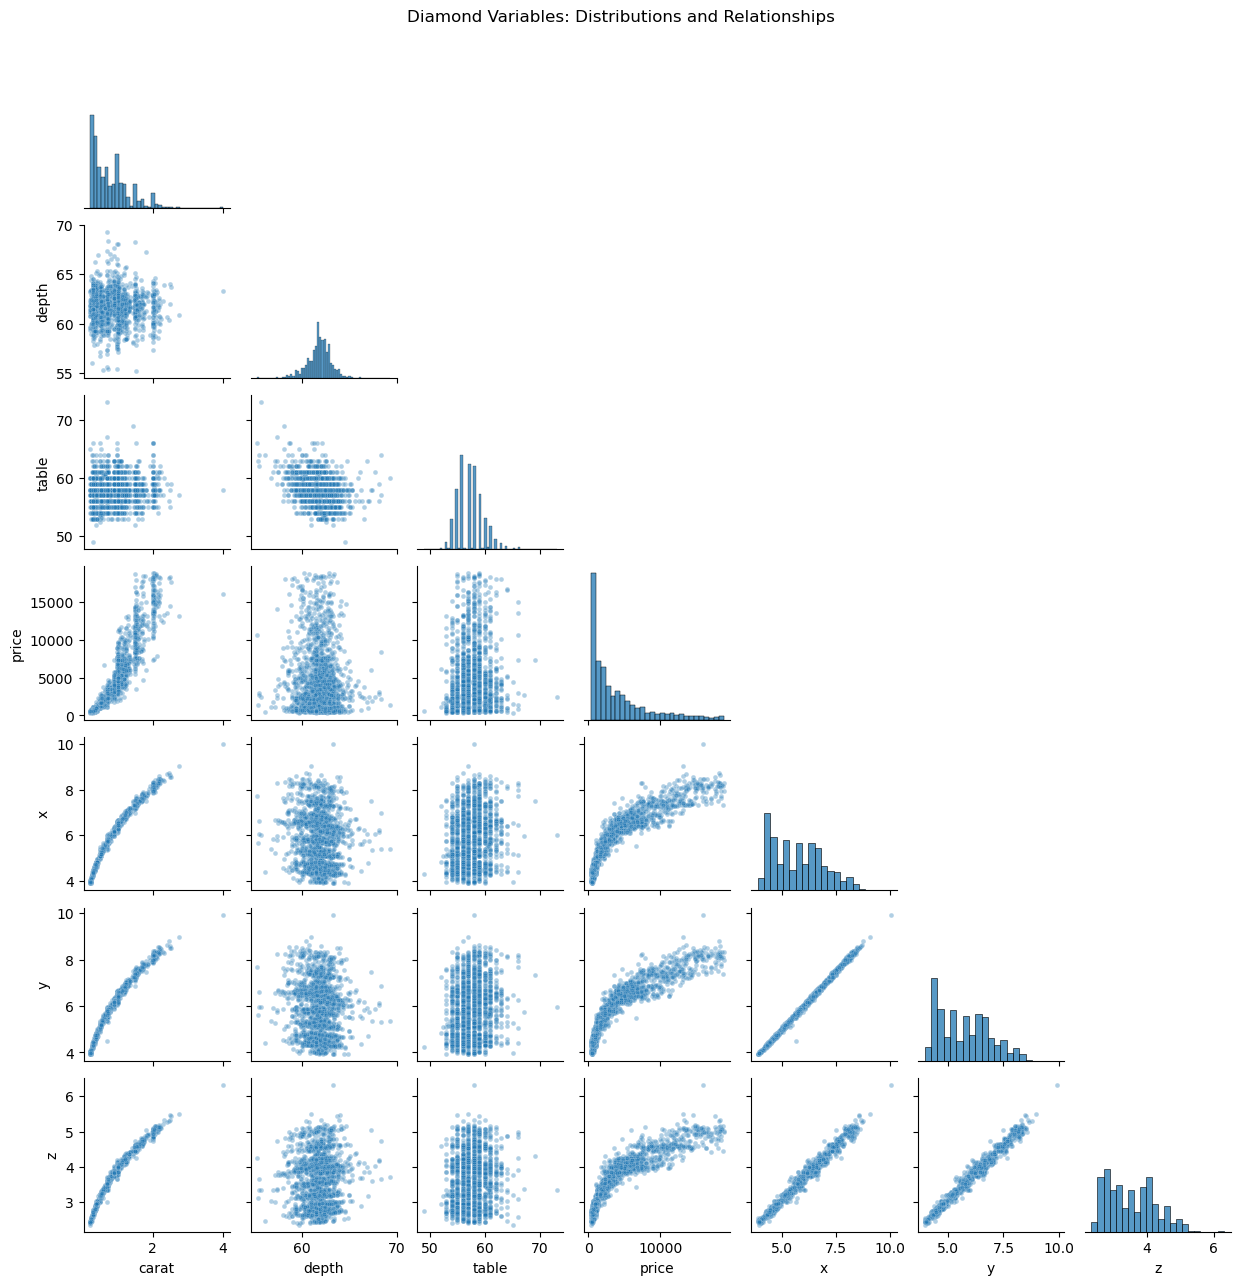

In [90]:
# Step 7: explore pairwise relationships and variable distributions
import matplotlib.pyplot as plt
import seaborn as sns

# Keep measured numeric columns; category ranks are not included in this plot.
pairplot_df = diamonds_numeric_df

# Use a reproducible sample so the pairplot renders quickly on the full dataset.
pairplot_sample = pairplot_df.sample(
    n=min(2000, len(pairplot_df)), random_state=42
)

# Show distributions on the diagonal and pairwise scatterplots in the lower triangle.
pairplot = sns.pairplot(
    pairplot_sample,
    diag_kind="hist",
    corner=True,
    height=1.8,
    plot_kws={"alpha": 0.35, "s": 12},
)

# Add a figure-level title and display the completed plot.
pairplot.fig.suptitle("Diamond Variables: Distributions and Relationships", y=1.02)
plt.show()

## Step 7: Pairplot interpretation

The diagonal histograms show the distribution of each numeric variable. The scatterplots below the diagonal show pairwise relationships between variables.

- **Carat and price:** Price generally increases as carat increases, with a curved pattern rather than a perfectly straight line.
- **Dimensions:** `x`, `y`, and `z` move closely together and each tends to increase with price. Their strong relationships with one another suggest that some dimensions may provide overlapping information.
- **Depth and table:** Their plots show no clear strong relationship with price compared with carat and the dimensions.
- **Distributions and unusual points:** `price` is right-skewed, and a few observations appear far from the main clusters. These are worth checking in the outlier step, but should not be removed based on this plot alone.

This plot uses a reproducible sample of up to 2,000 rows and includes only numeric measurements. Treat these patterns as exploratory; the correlation matrix and later outlier checks provide additional evidence.

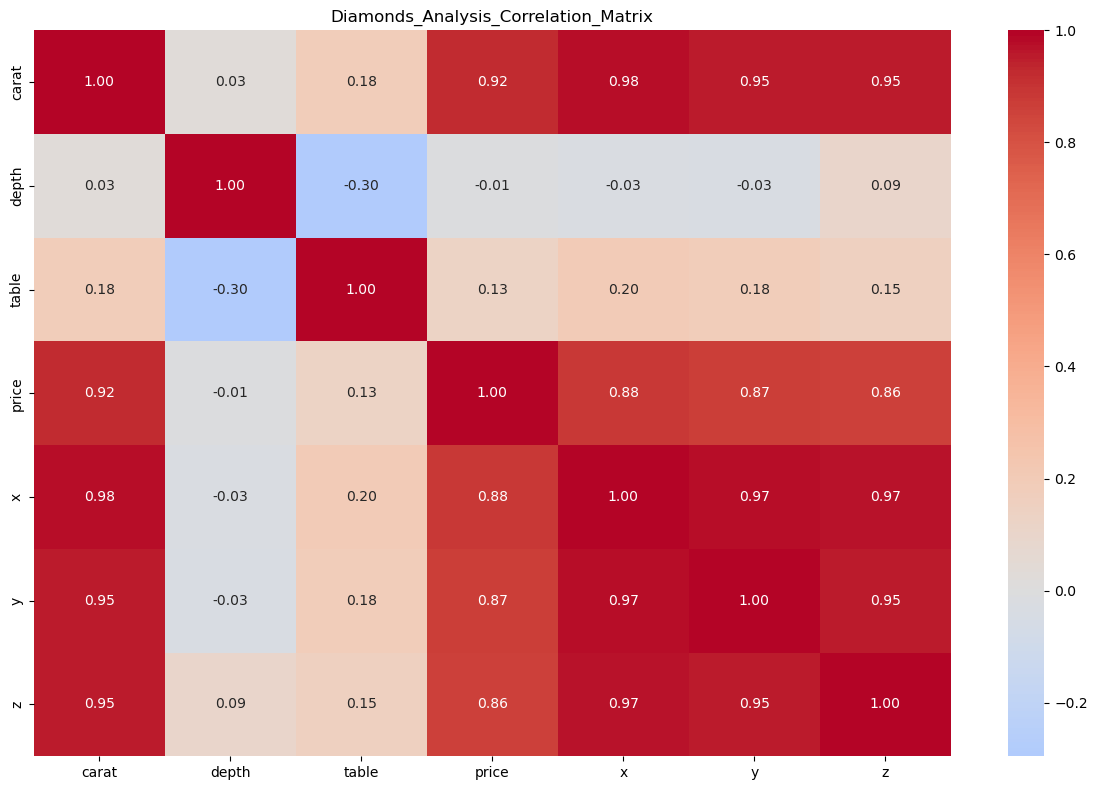

z        0.861249
y        0.865421
x        0.884435
table    0.127134
price    1.000000
depth   -0.010647
carat    0.921591
Name: price, dtype: float64

In [91]:
# import libraries for creating charts and seaborn for statistical visualization

import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = diamonds_numeric_df.corr()

# Create a figure for the correlation heatmap.

plt.figure(figsize=(12,8))

# Display correlation values using color intensity and numeric annotations.

sns.heatmap(correlation_matrix, annot=True, fmt = ".2f", cmap="coolwarm", center=0)
plt.title("Diamonds_Analysis_Correlation_Matrix")
plt.tight_layout()
plt.show()

correlation_matrix["price"].sort_index(ascending=False)


## Correlation and Pairplot Conclusions

The heatmap shows that `depth` and `table` have weak linear correlations with the dependent variable, `price`. For this initial linear-regression analysis, we will leave these two features out of the model dataset, while keeping the original `diamonds_df` unchanged.

The pairplot shows that `x`, `y`, and `z` are strongly related to one another. These measurements describe a diamond's physical dimensions, so they naturally tend to increase together. Including all three may introduce multicollinearity: the model's individual coefficients can become less stable and harder to interpret, while the features provide overlapping information.

To represent overall diamond size with two feature, we will keep `carat` and exclude `y`, and `z` from the initial model dataset. Carat measures weight rather than a geometric dimension, but it is a useful overall size measure and has a strong relationship with price. We can later compare this feature choice using model validation.

In [92]:
# Remove features excluded from the initial linear-regression dataset.
diamonds_numeric_df_model = diamonds_numeric_df.drop(
    columns=["depth", "table", "y", "z"]
)
diamonds_numeric_df_model.head()

,carat,price,x
0,0.23,326,3.95
1,0.21,326,3.89
2,0.23,327,4.05
3,0.29,334,4.20
4,0.31,335,4.34


In [93]:
# Determing outliers and IQR
Q1 = diamonds_numeric_df_model[["carat", "price", "x"]].quantile(0.25)
Q3 = diamonds_numeric_df_model[["carat", "price", "x"]].quantile(0.75)

IQR = Q3 - Q1
print(Q1)
print(Q3)
print(IQR)

carat      0.40
price    950.00
x          4.71
Name: 0.25, dtype: float64
carat       1.04
price    5324.25
x           6.54
Name: 0.75, dtype: float64
carat       0.64
price    4374.25
x           1.83
dtype: float64


In [97]:
# Filter rows with outliers in the selected predictor columns.
selected_columns = ["carat", "x"]

# Calculate IQR bounds for those columns; the upper bound adds 1.5 IQR.
Q1 = diamonds_numeric_df_model[selected_columns].quantile(0.25)
Q3 = diamonds_numeric_df_model[selected_columns].quantile(0.75)
IQR = Q3 - Q1
lower_bound_outlier = Q1 - 1.5 * IQR
upper_bound_outlier = Q3 + 1.5 * IQR

# Keep rows that fall within both selected columns' bounds.
outlier_mask = (
    diamonds_numeric_df_model[selected_columns].ge(lower_bound_outlier)
    & diamonds_numeric_df_model[selected_columns].le(upper_bound_outlier)
).all(axis=1)

diamonds_numeric_df_no_outliers = diamonds_numeric_df_model.loc[outlier_mask].copy()
diamonds_numeric_df_no_outliers

,carat,price,x
0,0.23,326,3.95
1,0.21,326,3.89
2,0.23,327,4.05
3,0.29,334,4.20
4,0.31,335,4.34
...,...,...,...
53935,0.72,2757,5.75
53936,0.72,2757,5.69
53937,0.70,2757,5.66
53938,0.86,2757,6.15


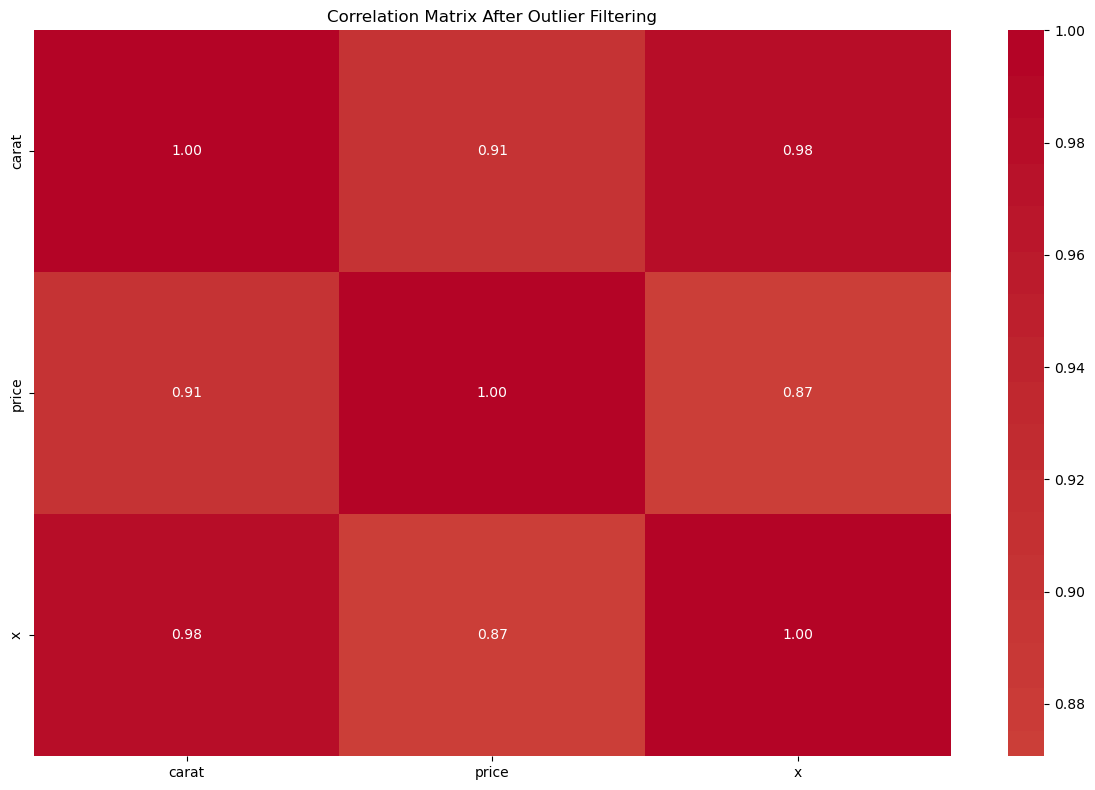

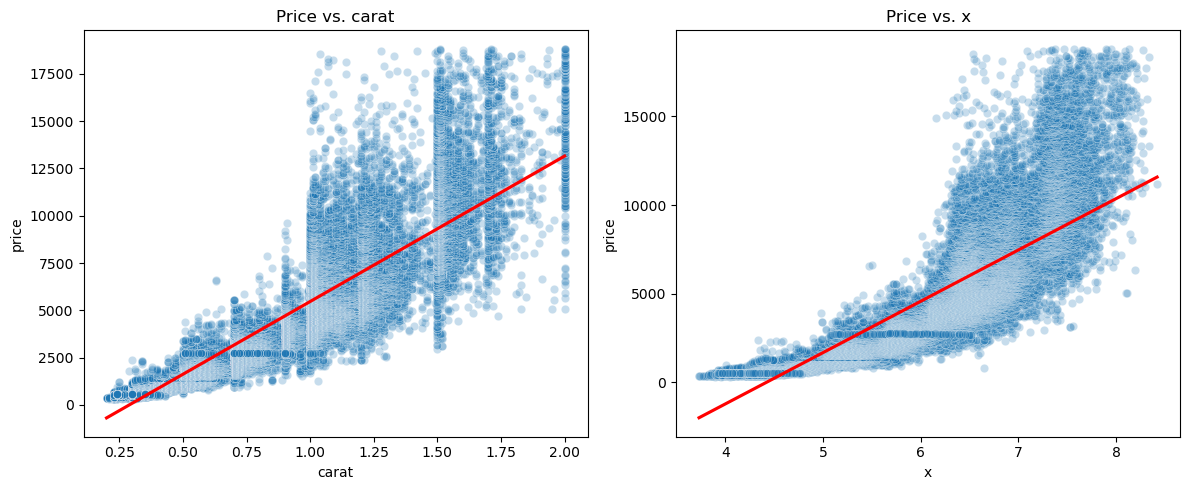

carat    0.905158
x        0.870665
Name: price, dtype: float64


In [111]:
# Recalculate correlations after the outlier filter.
correlation_matrix = diamonds_numeric_df_no_outliers.corr()

# Display the correlation matrix for the filtered data.
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix After Outlier Filtering")
plt.tight_layout()
plt.show()

# Rank predictor variables by their absolute correlation with price.
price_correlations = correlation_matrix["price"].drop("price").abs().sort_values(ascending=False)
selected_variables = price_correlations.index

# Create one scatterplot for each predictor, with a red linear regression line.
fig, axes = plt.subplots(
    1, len(selected_variables), figsize=(6 * len(selected_variables), 5), squeeze=False
)
for axis, variable in zip(axes.ravel(), selected_variables):
    sns.scatterplot(
        data=diamonds_numeric_df_no_outliers,
        x=variable,
        y="price",
        alpha=0.25,
        ax=axis,
    )
    sns.regplot(
        data=diamonds_numeric_df_no_outliers,
        x=variable,
        y="price",
        scatter=False,
        color="red",
        ax=axis,
    )
    axis.set_title(f"Price vs. {variable}")

plt.tight_layout()
plt.show()
print(price_correlations)

In [ ]:
diamonds_model_df = diamonds_numeric_df_no_outliers.join(quality_df[["cut_rank", "color_rank", "clarity_rank"]])
diamonds_model_df

,carat,price,x,cut_rank,color_rank,clarity_rank
0,0.23,326,3.95,5,6,2
1,0.21,326,3.89,4,6,3
2,0.23,327,4.05,2,6,5
3,0.29,334,4.20,4,2,4
4,0.31,335,4.34,2,1,2
...,...,...,...,...,...,...
53935,0.72,2757,5.75,5,7,3
53936,0.72,2757,5.69,2,7,3
53937,0.70,2757,5.66,3,7,3
53938,0.86,2757,6.15,4,3,2


In [104]:
# Train test split

from sklearn.model_selection import train_test_split

X = diamonds_model_df.drop("price", axis=1)
y = diamonds_model_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)


In [105]:
from sklearn.linear_model import LinearRegression

regression_model = LinearRegression()

regression_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [106]:
print(f"Coeficient values: {regression_model.coef_}")
print(f"Intercept coeficient value: {regression_model.intercept_}")

Coeficient values: [13166.75042317 -1763.89938298   168.01576089   329.21287992
   486.97362542]
Intercept coeficient value: -493.9416948183766


In [108]:
y_pred = regression_model.predict(X_test)

from sklearn.metrics import r2_score

print(f"R2 score for model is: {r2_score(y_test, y_pred)}")

R2 score for model is: 0.9000901591032223
